1. Importação das funções

In [ ]:
%reload_ext autoreload
%autoreload 2

from IPython.display import Audio, display

from mandarinstudio.audio.recording import record_audio
from mandarinstudio.audio.reference import generate_audio_ref
from mandarinstudio.comparison.dtw import run_dtw
from mandarinstudio.comparison.evaluation import evaluate_pronunciation
from mandarinstudio.visualization.graphs import plot_graph

from mandarinstudio.config import AUDIO_FOLDER

2. Bloco de testes do pipeline completo

In [9]:
hanzi = "哥哥"
pinyin = "ge1ge"

ref_path = generate_audio_ref(hanzi)
display(Audio(data=ref_path, rate=16000))

user_path = record_audio(AUDIO_FOLDER / 'user_audio.wav')
display(Audio(data=user_path, rate=16000))

2026-09-13 18:24:36,843 [WARNING] gtts.lang: 'zh-CN' has been deprecated, falling back to 'zh-CN'. This fallback will be removed in a future version.


>>> Fale a sílaba...


2026-09-13 18:24:39,549 [INFO] mandarinstudio.audio.recording: Gravação finalizada.


PronunciationResult(category=<CategoryOptions.MODERATE: 'moderate'>, similarity=66.76879961769546, spoken_pinyin='ge1 ge1', hanzi='哥哥')


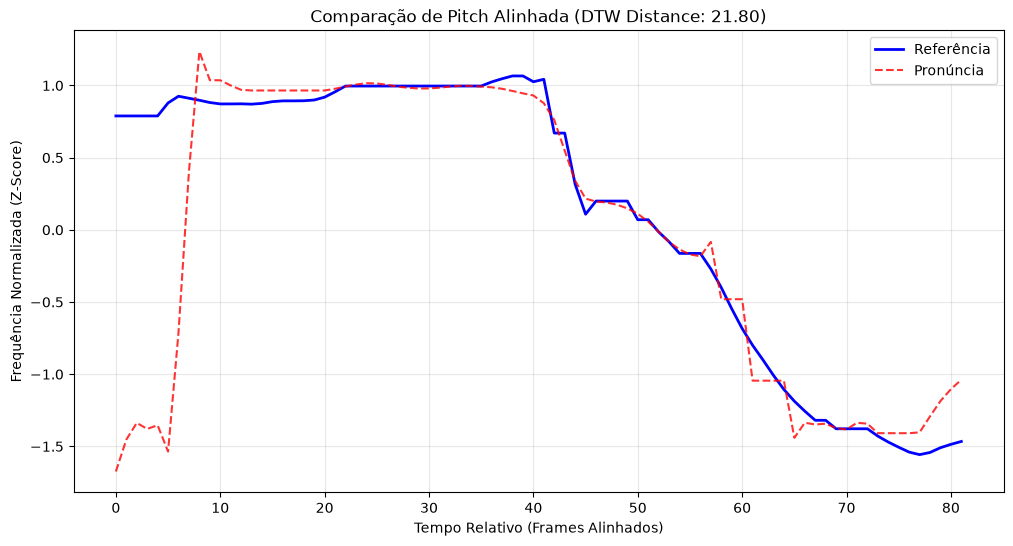

In [10]:
result = evaluate_pronunciation(ref_path, user_path, target_pinyin=pinyin)
print(result)

dtw_result = run_dtw(ref_path, user_path)
plot_graph(dtw_result.ref_pitch, dtw_result.user_pitch, dtw_result.path, dtw_result.distance)